# Labeled images needed vs. layers fine-tuned

For each victim (ResNet-18, VGG-11-BN, small CNN), the first *K* layers are kept frozen at
their CPA-recovered weights and the remaining layers (plus their BatchNorm) are re-initialized
and trained on a class-balanced subset of *N* labeled CIFAR-10 images
(*N* = 10, 20, 50, ..., 50000). Plotted: the smallest *N* whose fine-tuned model reaches
test accuracy >= victim - 1.1 points, vs. layers fine-tuned = depth - *K*.
The star at x = depth is the surrogate trained entirely from scratch.

Data: `data/fig_data_vs_layers.csv` (from `postprocess.py`, raw cells written by
`../run_sweep.sbatch`).

In [1]:
import os
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, MultipleLocator, NullFormatter, NullLocator

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [2]:
# Shared style of the two fine-tuning figures.
SURFACE = '#fcfcfb'                    # figure / axes background
INK_2 = '#52514e'                      # legend text, white-box line
GRID = '#e1e0d9'
ARCH_ORDER = ['ResNet-18', 'VGG-11', 'CNN']
ARCH_COLORS = {'ResNet-18': '#2a78d6', 'VGG-11': '#eb6834', 'CNN': '#009e73'}
ARCH_MARKERS = {'ResNet-18': 'o', 'VGG-11': '^', 'CNN': 's'}
SHORT = {'ResNet-18': 'ResNet', 'VGG-11': 'VGG', 'CNN': 'CNN'}
LEGEND_ORDER = ('CNN', 'VGG-11', 'ResNet-18')
SCRATCH_MARKER = '*'                   # the from-scratch surrogate, at x = n_layers
MAX_LAYERS = 21                        # x axis 1..21 (ResNet-18 depth)


def style_axes(ax):
    ax.set_facecolor(SURFACE)
    ax.set_axisbelow(True)
    ax.grid(True, color=GRID, linewidth=0.8)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color('black')
    ax.tick_params(colors='black', labelsize=11.5, length=0)


def layers_axis(ax):
    """x = layers fine-tuned, 1..21; every layer ticked, odd ones labelled."""
    ticks = list(range(1, MAX_LAYERS + 1))
    ax.set_xlim(0, MAX_LAYERS + 1)
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.set_xticklabels([str(t) if t % 2 else '' for t in ticks])
    ax.tick_params(axis='x', labelsize=13)
    ax.set_xlabel('Layers fine-tuned', color='black', fontsize=15)


def save(fig, path):
    fig.tight_layout()
    fig.savefig(path, format='pdf', bbox_inches='tight', facecolor=SURFACE)
    print(f"-> {path}")

In [3]:
df = pd.read_csv('data/fig_data_vs_layers.csv')
df

,arch,label,n_layers,num_recovered,layers_finetuned,is_surrogate,labeled_images,victim_acc,threshold_acc
0,resnet18,ResNet-18,21,19,2,False,10,92.59,91.49
1,resnet18,ResNet-18,21,17,4,False,20,92.59,91.49
2,resnet18,ResNet-18,21,14,7,False,50,92.59,91.49
3,resnet18,ResNet-18,21,20,1,False,10,92.59,91.49
4,resnet18,ResNet-18,21,18,3,False,10,92.59,91.49
5,resnet18,ResNet-18,21,16,5,False,10,92.59,91.49
6,resnet18,ResNet-18,21,12,9,False,10000,92.59,91.49
7,resnet18,ResNet-18,21,8,13,False,50000,92.59,91.49
8,resnet18,ResNet-18,21,4,17,False,50000,92.59,91.49
9,resnet18,ResNet-18,21,15,6,False,20,92.59,91.49


-> ../plots/fig_data_vs_layers.pdf


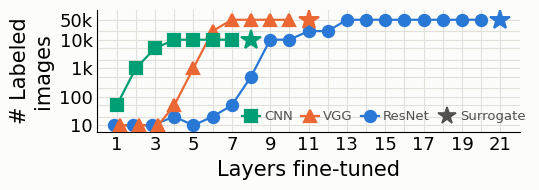

In [4]:
def plot_data_vs_layers(df, out, height=2.0):
    fig, ax = plt.subplots(figsize=(5.5, height), facecolor=SURFACE)
    style_axes(ax)
    series = []                          # (color, marker, n_layers, {x: images}), in CSV order
    for label in ARCH_ORDER:
        rows = df[(df['label'] == label) & df['labeled_images'].notna()]
        pts = {int(r.layers_finetuned): int(r.labeled_images) for r in rows.itertuples()}
        series.append((ARCH_COLORS[label], ARCH_MARKERS[label], int(rows['n_layers'].iloc[0]), pts))
    # Sizes are a discrete ladder, so different architectures often land on the very
    # same (x, y); those are spread along x, everything else stays on its tick.
    same = defaultdict(list)
    for idx, (_, _, _, pts) in enumerate(series):
        for x, y in pts.items():
            same[(x, y)].append(idx)
    shifted = defaultdict(dict)
    for (x, y), members in same.items():
        for rank, idx in enumerate(members):
            shifted[idx][x] = x + (rank - (len(members) - 1) / 2) * 0.32
    # Fine-tuned depths joined by a line; the surrogate star stands alone.
    for idx, (color, _, n_layers, pts) in enumerate(series):
        body = sorted(x for x in pts if x != n_layers)
        ax.plot([shifted[idx][x] for x in body], [pts[x] for x in body],
                color=color, ls='-', lw=1.6, zorder=4)
    for (x, y), members in same.items():
        for rank, idx in enumerate(members):
            dx = shifted[idx][x] - x
            color, marker, n_layers, _ = series[idx]
            star = x == n_layers
            ax.plot([x + dx], [y], ls='none', marker=SCRATCH_MARKER if star else marker,
                    ms=15 if star else 8, mec=color, mfc=color,
                    mew=1.4 if star else 1.6, zorder=6 if star else 5)

    ax.set_yscale('log')
    ax.yaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_minor_formatter(NullFormatter())
    sizes = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000, 100000, 200000]
    top = max(y for *_, pts in series for y in pts.values())
    ax.set_ylim(6, top * 2.2)            # headroom so the top-row stars are not clipped
    ax.yaxis.set_major_locator(FixedLocator([s for s in sizes if s <= top]))
    # Every size is ticked; only powers of ten and the top are labelled.
    ax.set_yticklabels([{10: '10', 100: '100', 1000: '1k', 10000: '10k',
                         50000: '50k', 100000: '100k', 200000: '200k'}.get(s, '')
                        if s in (10, 100, 1000, 10000, 50000, top) else ''
                        for s in sizes if s <= top])
    ax.set_ylabel('# Labeled\nimages' if height < 3 else '# Labeled images',
                  color='black', fontsize=15)
    ax.tick_params(axis='y', labelsize=13)
    layers_axis(ax)

    star = Line2D([], [], ls='none', marker=SCRATCH_MARKER, ms=13, mec=INK_2,
                  mfc=INK_2, mew=1.2, label='Surrogate')
    handles = [Line2D([], [], color=ARCH_COLORS[n], lw=1.6, marker=ARCH_MARKERS[n],
                      ms=8, mec=ARCH_COLORS[n], mfc=ARCH_COLORS[n], mew=1.6, label=SHORT[n])
               for n in LEGEND_ORDER] + [star]
    leg = ax.legend(handles=handles, loc='lower right', ncol=len(handles),
                    bbox_to_anchor=(1.04, -0.02), frameon=False, fontsize=9.5,
                    borderpad=0.3, columnspacing=0.6, handletextpad=0.3,
                    handlelength=1.4)
    for t in leg.get_texts():
        t.set_color(INK_2)
    save(fig, out)
    plt.show()


plot_data_vs_layers(df, '../plots/fig_data_vs_layers.pdf')